In [1]:
# !pip install torch torchvision librosa soundfile scikit-learn pandas numpy matplotlib seaborn tqdm
import os, zipfile, urllib.request, random
from pathlib import Path
import numpy as np
import pandas as pd
import librosa, librosa.display
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import warnings
warnings.filterwarnings("ignore")

SEED = 42
def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
set_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")
if device.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"  GPU: {torch.cuda.get_device_name(0)}")
    print(f"  VRAM: {p.total_memory/1e9:.1f} GB")
    print(f"  CUDA: {torch.version.cuda}")

Device: cuda
  GPU: NVIDIA GeForce MX250
  VRAM: 2.1 GB
  CUDA: 12.6


In [2]:
URL      = "https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip"
ZIP_PATH = Path("esc50.zip")
DATA_DIR = Path("ESC-50-master")

if not DATA_DIR.exists():
    if not ZIP_PATH.exists():
        print("Скачиваем архив (~600 МБ, один раз)...")
        def _progress(block_num, block_size, total_size):
            downloaded = block_num * block_size
            if total_size > 0 and block_num % 200 == 0:
                pct = 100 * downloaded / total_size
                print(f"\r  {downloaded/1e6:6.1f} / {total_size/1e6:.0f} МБ  ({pct:5.1f}%)",
                      end="", flush=True)
        urllib.request.urlretrieve(URL, ZIP_PATH, reporthook=_progress)
        print("\n  готово.")

    print("Распаковываем...")
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        members = zf.infolist()
        with tqdm(total=len(members), desc="  extract", unit="file") as pbar:
            for m in members:
                zf.extract(m, ".")
                pbar.update(1)
else:
    print(f"Каталог {DATA_DIR} уже существует — пропускаем.")

assert (DATA_DIR / "meta" / "esc50.csv").exists()
assert (DATA_DIR / "audio").is_dir()
print(f"WAV-файлов: {len(list((DATA_DIR / 'audio').glob('*.wav')))}")

Каталог ESC-50-master уже существует — пропускаем.
WAV-файлов: 2000


In [3]:
meta  = pd.read_csv(DATA_DIR / "meta" / "esc50.csv")
esc10 = meta[meta["esc10"] == True].reset_index(drop=True)

le = LabelEncoder()
esc10["label"] = le.fit_transform(esc10["category"])

y_all     = esc10["label"].values.astype(np.int64)
folds_arr = esc10["fold"].values
classes   = list(le.classes_)

print(f"Размер ESC-10: {esc10.shape}")
print(esc10["category"].value_counts().to_string())
print(f"\nКлассы: {classes}")

Размер ESC-10: (400, 8)
category
dog               40
chainsaw          40
crackling_fire    40
helicopter        40
rain              40
crying_baby       40
clock_tick        40
sneezing          40
rooster           40
sea_waves         40

Классы: ['chainsaw', 'clock_tick', 'crackling_fire', 'crying_baby', 'dog', 'helicopter', 'rain', 'rooster', 'sea_waves', 'sneezing']


sr=44100, duration=5.00s


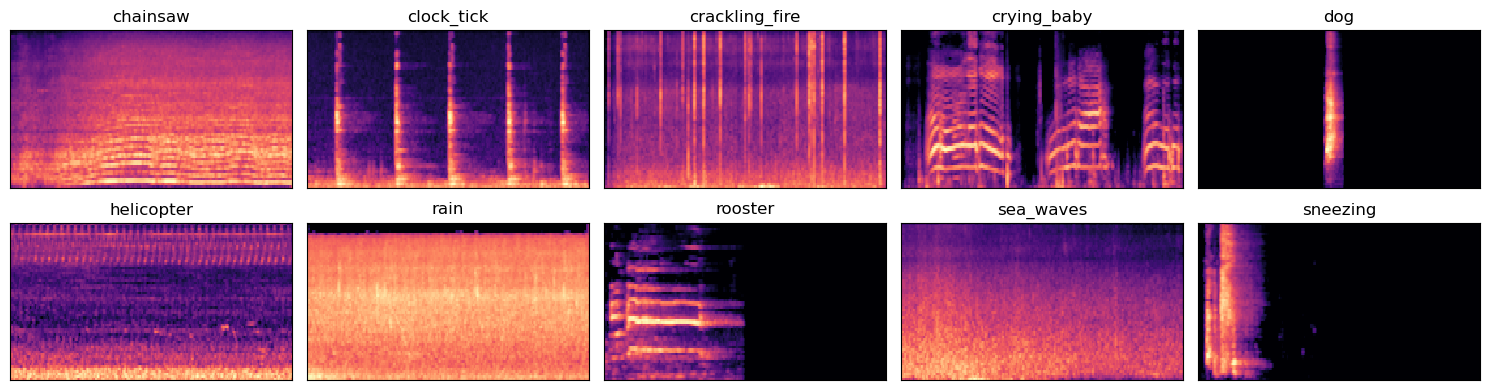

In [4]:
sample_path = DATA_DIR / "audio" / esc10.loc[0, "filename"]
y, sr = librosa.load(sample_path, sr=None)
print(f"sr={sr}, duration={len(y)/sr:.2f}s")

fig, axes = plt.subplots(2, 5, figsize=(15, 4))
for ax, cat in zip(axes.ravel(), classes):
    row = esc10[esc10["category"] == cat].iloc[0]
    y, sr = librosa.load(DATA_DIR / "audio" / row["filename"], sr=22050)
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=64)
    librosa.display.specshow(librosa.power_to_db(S), sr=sr, ax=ax, cmap="magma")
    ax.set_title(cat); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [5]:
SR, N_FFT, HOP = 22050, 2048, 512
TARGET_FRAMES  = 216
N_MELS         = 128

def trim_silence(y, top_db=20):
    _, (s, e) = librosa.effects.trim(y, top_db=top_db)
    return y[s:e]

# --- 4.1 MFCC-статистики для sklearn ---
def mfcc_stats(path, n_mfcc=40):
    y, _ = librosa.load(path, sr=SR)
    y = trim_silence(y)
    if len(y) < N_FFT:
        y = np.pad(y, (0, N_FFT - len(y)))
    m  = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP)
    d1 = librosa.feature.delta(m, order=1)
    return np.concatenate([m.mean(1), m.std(1), d1.mean(1), d1.std(1)])   # 160

print("Извлекаем MFCC-статистики...")
X_mfcc = np.stack([
    mfcc_stats(DATA_DIR / "audio" / fn)
    for fn in tqdm(esc10["filename"], desc="  mfcc")
]).astype(np.float32)
print(" ", X_mfcc.shape)


# --- 4.2 Лог-мел-спектрограммы для CNN/CRNN ---
def logmel(path):
    y, _ = librosa.load(path, sr=SR)
    y = trim_silence(y)
    S  = librosa.feature.melspectrogram(y=y, sr=SR, n_mels=N_MELS,
                                        n_fft=N_FFT, hop_length=HOP)
    S  = librosa.power_to_db(S, ref=np.max)
    if S.shape[1] < TARGET_FRAMES:
        S = np.pad(S, ((0,0),(0, TARGET_FRAMES - S.shape[1])),
                   mode="constant", constant_values=S.min())
    else:
        S = S[:, :TARGET_FRAMES]
    return S.astype(np.float32)

print("\nИзвлекаем лог-мел-спектрограммы...")
X_spec = np.stack([
    logmel(DATA_DIR / "audio" / fn)
    for fn in tqdm(esc10["filename"], desc="  logmel")
])                                                   # (400, 128, 216)
X_spec = np.transpose(X_spec, (0, 2, 1))            # (400, 216, 128)
X_spec = X_spec[:, None, :, :].astype(np.float32)    # (400, 1, 216, 128)

# Per-sample нормализация (mean=0, std=1 для каждого файла отдельно)
mu  = X_spec.mean(axis=(1, 2, 3), keepdims=True)
sig = X_spec.std(axis=(1, 2, 3), keepdims=True) + 1e-6
X_spec = (X_spec - mu) / sig
print(f"  normalized: {X_spec.shape}, "
      f"min={X_spec.min():.2f}, max={X_spec.max():.2f}")


# --- 4.3 MFCC-последовательности для BiLSTM (СЫРЫЕ, без нормализации) ---
# Нормализацию делаем позже на train-фолде, чтобы не потерять информацию об энергии.
def mfcc_seq(path, n_mfcc=40):
    y, _ = librosa.load(path, sr=SR)
    y = trim_silence(y)
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_mfcc, hop_length=HOP)
    if m.shape[1] < TARGET_FRAMES:
        m = np.pad(m, ((0,0),(0, TARGET_FRAMES - m.shape[1])), mode="constant")
    else:
        m = m[:, :TARGET_FRAMES]
    return m.T                                       # (T, F)

print("\nИзвлекаем MFCC-последовательности (сырые)...")
X_seq = np.stack([
    mfcc_seq(DATA_DIR / "audio" / fn)
    for fn in tqdm(esc10["filename"], desc="  mfcc-seq")
]).astype(np.float32)
print(f"  {X_seq.shape}  (паддинг нулями; нормализация будет в кросс-валидации)")

np.savez_compressed("esc10_features.npz",
                    X_mfcc=X_mfcc, X_spec=X_spec, X_seq=X_seq,
                    y=y_all, folds=folds_arr)
print("\nПризнаки сохранены в esc10_features.npz")

Извлекаем MFCC-статистики...


  mfcc:   0%|          | 0/400 [00:00<?, ?it/s]

  (400, 160)

Извлекаем лог-мел-спектрограммы...


  logmel:   0%|          | 0/400 [00:00<?, ?it/s]

  normalized: (400, 1, 216, 128), min=-9.70, max=8.81

Извлекаем MFCC-последовательности (сырые)...


  mfcc-seq:   0%|          | 0/400 [00:00<?, ?it/s]

  (400, 216, 40)  (паддинг нулями; нормализация будет в кросс-валидации)

Признаки сохранены в esc10_features.npz


In [6]:
folds = [(np.where(folds_arr != f)[0], np.where(folds_arr == f)[0])
         for f in range(1, 6)]

results = []

def evaluate(y_true, y_pred, name):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average="macro")
    print(f"{name:28s}  acc={acc:.3f}  macro-F1={f1:.3f}")
    r = {"model": name, "acc": acc, "f1": f1,
         "y_true": np.array(y_true), "y_pred": np.array(y_pred)}
    results.append(r)
    return r

In [7]:
def run_sklearn_model(make_clf, X, y, name, scale=True):
    all_true, all_pred = [], []
    for tr, te in tqdm(folds, desc=name, leave=True):
        Xtr, Xte = X[tr], X[te]
        if scale:
            sc = StandardScaler().fit(Xtr)
            Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
        clf = make_clf()
        clf.fit(Xtr, y[tr])
        pred = clf.predict(Xte)
        all_true.extend(y[te]); all_pred.extend(pred)
    return evaluate(all_true, all_pred, name)

run_sklearn_model(
    lambda: LogisticRegression(max_iter=2000, C=1.0, multi_class="multinomial"),
    X_mfcc, y_all, "LogReg + MFCC"
)
run_sklearn_model(
    lambda: SVC(kernel="rbf", C=10, gamma="scale"),
    X_mfcc, y_all, "SVM-RBF + MFCC"
)
run_sklearn_model(
    lambda: RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=SEED),
    X_mfcc, y_all, "RandomForest + MFCC", scale=False
)

LogReg + MFCC:   0%|          | 0/5 [00:00<?, ?it/s]

LogReg + MFCC                 acc=0.820  macro-F1=0.819


SVM-RBF + MFCC:   0%|          | 0/5 [00:00<?, ?it/s]

SVM-RBF + MFCC                acc=0.820  macro-F1=0.821


RandomForest + MFCC:   0%|          | 0/5 [00:00<?, ?it/s]

RandomForest + MFCC           acc=0.792  macro-F1=0.790


{'model': 'RandomForest + MFCC',
 'acc': 0.7925,
 'f1': 0.7904959054941514,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3, 3, 3, 

In [8]:
class AudioDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(np.ascontiguousarray(X)).float()
        self.y = torch.from_numpy(np.ascontiguousarray(y)).long()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.y[i]


class SeqDataset(Dataset):
    """Для LSTM: возвращает ещё маску реальных (не паддинг) кадров."""
    def __init__(self, X, y):
        self.X    = torch.from_numpy(np.ascontiguousarray(X)).float()
        self.y    = torch.from_numpy(np.ascontiguousarray(y)).long()
        # Паддинг у нас ровно нули → кадр с нулевой суммой считаем за паддинг
        self.mask = (self.X.abs().sum(-1) > 0).float()
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.X[i], self.mask[i], self.y[i]


def spec_augment_batch(x, fill=0.0):
    """Мягкий SpecAugment: по одной маске на время и на частоту."""
    if x.dim() != 4:
        return x
    B, C, H, W = x.shape
    x = x.clone()
    for b in range(B):
        if W > 20:
            t0 = torch.randint(0, W - 20, (1,)).item()
            x[b, :, :, t0:t0+20] = fill
        if H > 10:
            f0 = torch.randint(0, H - 10, (1,)).item()
            x[b, :, f0:f0+10, :] = fill
    return x


def train_one_fold(model, Xtr, ytr, Xte, yte,
                   epochs=120, batch_size=16, lr=5e-4,
                   patience=20, augment=False, seq=False, fold_tag=""):
    """Общий тренировочный цикл для CNN/CRNN (4D-вход)."""
    tr_loader = DataLoader(AudioDataset(Xtr, ytr), batch_size=batch_size,
                           shuffle=True, pin_memory=(device.type == "cuda"))
    te_loader = DataLoader(AudioDataset(Xte, yte), batch_size=64,
                           shuffle=False, pin_memory=(device.type == "cuda"))

    model     = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=6, min_lr=1e-5)
    criterion = nn.CrossEntropyLoss()

    best_acc, best_state, no_improve = 0.0, None, 0
    ep_bar = tqdm(range(epochs), desc=f"  {fold_tag}", leave=False)

    for epoch in ep_bar:
        model.train(); run_loss = 0.0
        for X, y in tr_loader:
            X, y = X.to(device), y.to(device)
            if augment:
                X = spec_augment_batch(X)
            optimizer.zero_grad()
            loss = criterion(model(X), y)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * X.size(0)
        train_loss = run_loss / len(tr_loader.dataset)

        model.eval(); correct = total = 0
        with torch.no_grad():
            for X, y in te_loader:
                preds = model(X.to(device)).argmax(1)
                correct += (preds == y.to(device)).sum().item()
                total   += y.size(0)
        val_acc = correct / total
        scheduler.step(val_acc)
        ep_bar.set_postfix(loss=f"{train_loss:.3f}", val=f"{val_acc:.3f}",
                           lr=f"{optimizer.param_groups[0]['lr']:.1e}")

        if val_acc > best_acc:
            best_acc, no_improve = val_acc, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            no_improve += 1
            if no_improve >= patience:
                break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model


def predict_nn(model, X, seq=False, batch_size=64):
    model.eval()
    if seq:
        loader = DataLoader(SeqDataset(X, np.zeros(len(X), dtype=np.int64)),
                            batch_size=batch_size, shuffle=False)
    else:
        loader = DataLoader(AudioDataset(X, np.zeros(len(X), dtype=np.int64)),
                            batch_size=batch_size, shuffle=False)
    out = []
    with torch.no_grad():
        for batch in loader:
            if seq:
                Xb, mask, _ = batch
                out.append(model(Xb.to(device), mask.to(device)).argmax(1).cpu().numpy())
            else:
                Xb, _ = batch
                out.append(model(Xb.to(device)).argmax(1).cpu().numpy())
    return np.concatenate(out)


def run_nn_experiment(build_fn, X, y, name, epochs=120, augment=False):
    all_true, all_pred = [], []
    fold_bar = tqdm(enumerate(folds, 1), total=len(folds), desc=name, position=0)
    for fold_idx, (tr, te) in fold_bar:
        model = train_one_fold(build_fn(), X[tr], y[tr], X[te], y[te],
                               epochs=epochs, augment=augment,
                               fold_tag=f"{name} f{fold_idx}")
        pred = predict_nn(model, X[te], seq=False)
        all_true.extend(y[te]); all_pred.extend(pred)
    return evaluate(all_true, all_pred, name)

In [9]:
def normalize_seq_train_only(Xtr, Xte):
    """Per-feature стандартизация. Параметры (mu, sig) fit на train-фолде.
       Паддинг (нули) остаётся нулями."""
    F = Xtr.shape[-1]
    flat_tr = Xtr.reshape(-1, F)
    real_tr = Xtr.sum(-1).reshape(-1) != 0
    mu  = flat_tr[real_tr].mean(0)
    sig = flat_tr[real_tr].std(0) + 1e-6
    Xtr_n = (Xtr - mu) / sig
    Xte_n = (Xte - mu) / sig
    Xtr_n[Xtr.sum(-1) == 0] = 0
    Xte_n[Xte.sum(-1) == 0] = 0
    return Xtr_n.astype(np.float32), Xte_n.astype(np.float32)


class BiLSTM(nn.Module):
    def __init__(self, n_features=40, n_classes=10, hidden=64):
        super().__init__()
        self.lstm1 = nn.LSTM(n_features, hidden, batch_first=True, bidirectional=True)
        self.drop1 = nn.Dropout(0.2)
        self.lstm2 = nn.LSTM(2*hidden, hidden, batch_first=True, bidirectional=True)
        self.drop2 = nn.Dropout(0.2)
        self.attn  = nn.Linear(2*hidden, 1)                  # attention по времени
        self.head  = nn.Sequential(
            nn.Linear(2*hidden, 64), nn.GELU(),
            nn.Linear(64, n_classes),
        )
    def forward(self, x, mask=None):
        h, _ = self.lstm1(x); h = self.drop1(h)
        h, _ = self.lstm2(h); h = self.drop2(h)
        if mask is not None:
            att = self.attn(h).squeeze(-1)                   # (B, T)
            att = att.masked_fill(mask == 0, float("-inf"))
            att = torch.softmax(att, dim=1).unsqueeze(-1)    # (B, T, 1)
            h = (h * att).sum(1)
        else:
            h = h.mean(1)
        return self.head(h)


def run_bilstm(X, y, name="BiLSTM + MFCC-seq",
               epochs=150, patience=25, lr=3e-4, batch_size=16):
    all_true, all_pred = [], []
    fold_bar = tqdm(enumerate(folds, 1), total=len(folds), desc=name, position=0)
    for fold_idx, (tr, te) in fold_bar:
        Xtr_n, Xte_n = normalize_seq_train_only(X[tr].copy(), X[te].copy())

        model     = BiLSTM().to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)   # без weight_decay
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=8, min_lr=1e-5)
        criterion = nn.CrossEntropyLoss()

        tr_loader = DataLoader(SeqDataset(Xtr_n, y[tr]), batch_size=batch_size,
                               shuffle=True, pin_memory=(device.type == "cuda"))
        te_loader = DataLoader(SeqDataset(Xte_n, y[te]), batch_size=64,
                               shuffle=False, pin_memory=(device.type == "cuda"))

        best_acc, best_state, no_improve = 0.0, None, 0
        ep_bar = tqdm(range(epochs), desc=f"  {name} f{fold_idx}", leave=False)
        for _ in ep_bar:
            model.train(); run_loss = 0.0
            for Xb, mask, yb in tr_loader:
                Xb, mask, yb = Xb.to(device), mask.to(device), yb.to(device)
                optimizer.zero_grad()
                loss = criterion(model(Xb, mask), yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                run_loss += loss.item() * Xb.size(0)
            train_loss = run_loss / len(tr_loader.dataset)

            model.eval(); correct = total = 0
            with torch.no_grad():
                for Xb, mask, yb in te_loader:
                    preds = model(Xb.to(device), mask.to(device)).argmax(1)
                    correct += (preds == yb.to(device)).sum().item()
                    total   += yb.size(0)
            val_acc = correct / total
            scheduler.step(val_acc)
            ep_bar.set_postfix(loss=f"{train_loss:.3f}", val=f"{val_acc:.3f}",
                               lr=f"{optimizer.param_groups[0]['lr']:.1e}")

            if val_acc > best_acc:
                best_acc, no_improve = val_acc, 0
                best_state = {k: v.detach().cpu().clone()
                              for k, v in model.state_dict().items()}
            else:
                no_improve += 1
                if no_improve >= patience:
                    break

        if best_state is not None:
            model.load_state_dict(best_state)
        pred = predict_nn(model, Xte_n, seq=True)
        all_true.extend(y[te]); all_pred.extend(pred)

    return evaluate(all_true, all_pred, name)


run_bilstm(X_seq, y_all)

BiLSTM + MFCC-seq:   0%|          | 0/5 [00:00<?, ?it/s]

  BiLSTM + MFCC-seq f1:   0%|          | 0/150 [00:00<?, ?it/s]

  BiLSTM + MFCC-seq f2:   0%|          | 0/150 [00:00<?, ?it/s]

  BiLSTM + MFCC-seq f3:   0%|          | 0/150 [00:00<?, ?it/s]

  BiLSTM + MFCC-seq f4:   0%|          | 0/150 [00:00<?, ?it/s]

  BiLSTM + MFCC-seq f5:   0%|          | 0/150 [00:00<?, ?it/s]

BiLSTM + MFCC-seq             acc=0.797  macro-F1=0.798


{'model': 'BiLSTM + MFCC-seq',
 'acc': 0.7975,
 'f1': 0.7981563452622467,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3, 3, 3, 9,

In [10]:
class CNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        # Ядра трактуются как (kernel_time, kernel_freq).
        # Чередуем "шире по частоте" и "шире по времени".
        self.features = nn.Sequential(
            nn.Conv2d(1,   32,  kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(32),  nn.GELU(), nn.MaxPool2d(2),

            nn.Conv2d(32,  64,  kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(64),  nn.GELU(), nn.MaxPool2d(2),

            nn.Conv2d(64,  128, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(128), nn.GELU(), nn.MaxPool2d(2),

            nn.Conv2d(128, 128, kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(128), nn.GELU(),

            nn.AdaptiveAvgPool2d((4, 4)),
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.25),
            nn.Linear(128 * 4 * 4, 256), nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(256, n_classes),
        )
    def forward(self, x):
        return self.head(self.features(x))


run_nn_experiment(lambda: CNN(), X_spec, y_all,
                  "CNN + log-mel (rect)", epochs=120, augment=True)

CNN + log-mel (rect):   0%|          | 0/5 [00:00<?, ?it/s]

  CNN + log-mel (rect) f1:   0%|          | 0/120 [00:00<?, ?it/s]

  CNN + log-mel (rect) f2:   0%|          | 0/120 [00:00<?, ?it/s]

  CNN + log-mel (rect) f3:   0%|          | 0/120 [00:00<?, ?it/s]

  CNN + log-mel (rect) f4:   0%|          | 0/120 [00:00<?, ?it/s]

  CNN + log-mel (rect) f5:   0%|          | 0/120 [00:00<?, ?it/s]

CNN + log-mel (rect)          acc=0.912  macro-F1=0.913


{'model': 'CNN + log-mel (rect)',
 'acc': 0.9125,
 'f1': 0.9125145066837461,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3, 3, 3,

In [11]:
class CRNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.cnn = nn.Sequential(
            nn.Conv2d(1,   32,  kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(32),  nn.GELU(), nn.MaxPool2d(2),

            nn.Conv2d(32,  64,  kernel_size=(5, 3), padding=(2, 1)),
            nn.BatchNorm2d(64),  nn.GELU(), nn.MaxPool2d(2),

            nn.Conv2d(64,  128, kernel_size=(3, 5), padding=(1, 2)),
            nn.BatchNorm2d(128), nn.GELU(), nn.MaxPool2d(2),
        )
        # (B, 128, 27, 16) -> (B, 128, 27, 1) -> (B, 128, 27) -> permute -> (B, 27, 128)
        self.freq_pool = nn.AdaptiveAvgPool2d((None, 1))
        self.lstm = nn.LSTM(128, 64, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(128, 64), nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(64, n_classes),
        )
    def forward(self, x):
        h = self.cnn(x)                               # (B, 128, 27, 16)
        h = self.freq_pool(h).squeeze(-1)             # (B, 128, 27)
        h = h.permute(0, 2, 1)                        # (B, 27, 128)
        h, _ = self.lstm(h)                           # (B, 27, 128)
        h = h.mean(1)
        return self.head(h)


run_nn_experiment(lambda: CRNN(), X_spec, y_all,
                  "CRNN + log-mel (rect)", epochs=120, augment=True)

CRNN + log-mel (rect):   0%|          | 0/5 [00:00<?, ?it/s]

  CRNN + log-mel (rect) f1:   0%|          | 0/120 [00:00<?, ?it/s]

  CRNN + log-mel (rect) f2:   0%|          | 0/120 [00:00<?, ?it/s]

  CRNN + log-mel (rect) f3:   0%|          | 0/120 [00:00<?, ?it/s]

  CRNN + log-mel (rect) f4:   0%|          | 0/120 [00:00<?, ?it/s]

  CRNN + log-mel (rect) f5:   0%|          | 0/120 [00:00<?, ?it/s]

CRNN + log-mel (rect)         acc=0.868  macro-F1=0.867


{'model': 'CRNN + log-mel (rect)',
 'acc': 0.8675,
 'f1': 0.8672014885666515,
 'y_true': array([4, 4, 0, 2, 5, 5, 5, 5, 5, 5, 6, 2, 2, 2, 2, 5, 5, 3, 0, 0, 0, 3,
        3, 3, 6, 1, 1, 3, 3, 9, 6, 7, 7, 8, 8, 6, 9, 4, 4, 9, 4, 7, 7, 1,
        8, 8, 7, 7, 2, 1, 7, 8, 7, 2, 0, 0, 9, 9, 1, 6, 9, 6, 6, 1, 9, 4,
        3, 3, 8, 1, 1, 6, 0, 0, 2, 9, 4, 8, 8, 4, 7, 6, 8, 3, 3, 9, 4, 4,
        4, 4, 6, 4, 9, 4, 9, 1, 4, 4, 8, 8, 1, 9, 9, 9, 1, 8, 8, 8, 1, 1,
        8, 1, 1, 3, 8, 2, 2, 5, 5, 5, 5, 2, 2, 2, 2, 5, 5, 5, 5, 3, 3, 0,
        0, 0, 0, 2, 2, 7, 3, 3, 0, 0, 7, 6, 6, 6, 0, 0, 3, 7, 6, 6, 9, 6,
        1, 9, 7, 7, 7, 7, 2, 2, 7, 7, 0, 0, 0, 0, 0, 0, 0, 2, 6, 7, 4, 7,
        6, 9, 6, 6, 1, 9, 9, 9, 6, 1, 4, 9, 8, 8, 7, 2, 2, 9, 7, 9, 1, 5,
        5, 5, 3, 3, 3, 3, 3, 3, 3, 3, 5, 5, 7, 4, 8, 8, 9, 6, 2, 6, 6, 4,
        2, 7, 4, 8, 8, 1, 0, 8, 4, 1, 1, 1, 1, 4, 4, 8, 2, 5, 5, 5, 5, 0,
        0, 9, 9, 9, 0, 0, 6, 6, 5, 5, 6, 7, 7, 7, 7, 6, 2, 2, 7, 0, 0, 6,
        8, 8, 8, 3, 3, 3

                model    acc       f1
 CNN + log-mel (rect) 0.9125 0.912515
CRNN + log-mel (rect) 0.8675 0.867201
       SVM-RBF + MFCC 0.8200 0.820904
        LogReg + MFCC 0.8200 0.819407
    BiLSTM + MFCC-seq 0.7975 0.798156
  RandomForest + MFCC 0.7925 0.790496


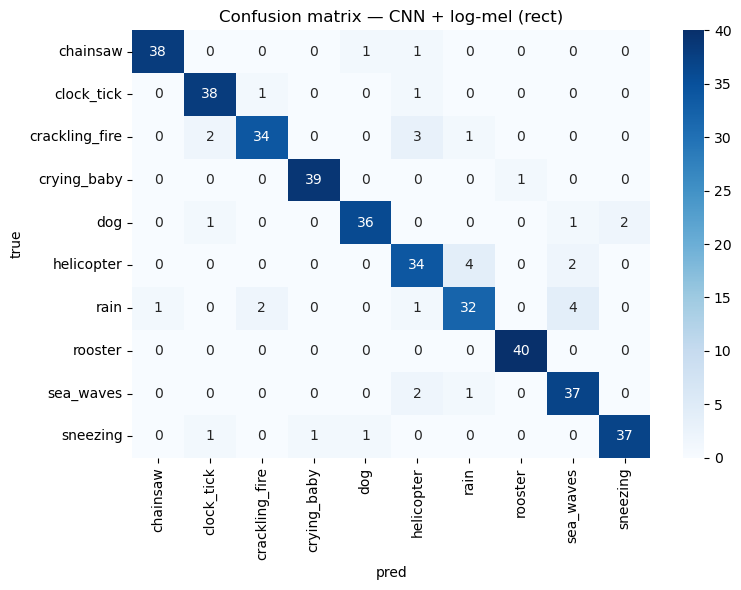

In [12]:
df = pd.DataFrame([{k: r[k] for k in ("model", "acc", "f1")} for r in results])
print(df.sort_values("acc", ascending=False).to_string(index=False))

best = max(results, key=lambda r: r["acc"])
cm = confusion_matrix(best["y_true"], best["y_pred"])
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=classes, yticklabels=classes)
plt.ylabel("true"); plt.xlabel("pred")
plt.title(f"Confusion matrix — {best['model']}")
plt.tight_layout(); plt.show()